# Customer Segmentation using K-Means and Hierarchical Clustering
**Dataset:** Wholesale Customers (UCI) – annual spending of 440 wholesale clients across product categories.

**Aim:** Implement K-Means and Hierarchical Clustering, use the Elbow Method and Dendrogram to determine the optimal number of clusters, and analyze the generated clusters on a real-world dataset.

## 1. Load the dataset

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import linkage, dendrogram

import warnings
warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
RANDOM_STATE = 42

In [4]:
df = pd.read_csv('/content/Wholesale customers data.csv')
df.head()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


In [5]:
print('Shape (rows, columns):', df.shape)
print()
df.info()

Shape (rows, columns): (440, 8)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 440 entries, 0 to 439
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Channel           440 non-null    int64
 1   Region            440 non-null    int64
 2   Fresh             440 non-null    int64
 3   Milk              440 non-null    int64
 4   Grocery           440 non-null    int64
 5   Frozen            440 non-null    int64
 6   Detergents_Paper  440 non-null    int64
 7   Delicassen        440 non-null    int64
dtypes: int64(8)
memory usage: 27.6 KB


In [6]:
print('Missing values per column:')
print(df.isnull().sum())
print('\nDuplicate rows:', df.duplicated().sum())

Missing values per column:
Channel             0
Region              0
Fresh               0
Milk                0
Grocery             0
Frozen              0
Detergents_Paper    0
Delicassen          0
dtype: int64

Duplicate rows: 0


In [7]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Channel,440.0,1.322727,0.468052,1.0,1.00,1.0,2.00,2.0
Region,440.0,2.543182,0.774272,1.0,2.00,3.0,3.00,3.0
Fresh,440.0,12000.297727,12647.328865,3.0,3127.75,8504.0,16933.75,112151.0
Milk,440.0,5796.265909,7380.377175,55.0,1533.00,3627.0,7190.25,73498.0
Grocery,440.0,7951.277273,9503.162829,3.0,2153.00,4755.5,10655.75,92780.0
Frozen,440.0,3071.931818,4854.673333,25.0,742.25,1526.0,3554.25,60869.0
Detergents_Paper,440.0,2881.493182,4767.854448,3.0,256.75,816.5,3922.00,40827.0
Delicassen,440.0,1524.870455,2820.105937,3.0,408.25,965.5,1820.25,47943.0


## 2. Select relevant features
We cluster on the six numerical spending features. `Channel` (Horeca / Retail) and `Region` are categorical group identifiers, so they are excluded from clustering. We keep `Channel` aside to validate the clusters later.

In [8]:
features = ['Fresh', 'Milk', 'Grocery', 'Frozen', 'Detergents_Paper', 'Delicassen']
X = df[features].copy()
X.head()

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,12669,9656,7561,214,2674,1338
1,7057,9810,9568,1762,3293,1776
2,6353,8808,7684,2405,3516,7844
3,13265,1196,4221,6404,507,1788
4,22615,5410,7198,3915,1777,5185


## 3. Data preprocessing

### 3.1 Missing values

In [9]:
print(X.isnull().sum())

Fresh               0
Milk                0
Grocery             0
Frozen              0
Detergents_Paper    0
Delicassen          0
dtype: int64


### 3.2 Outliers and skewness

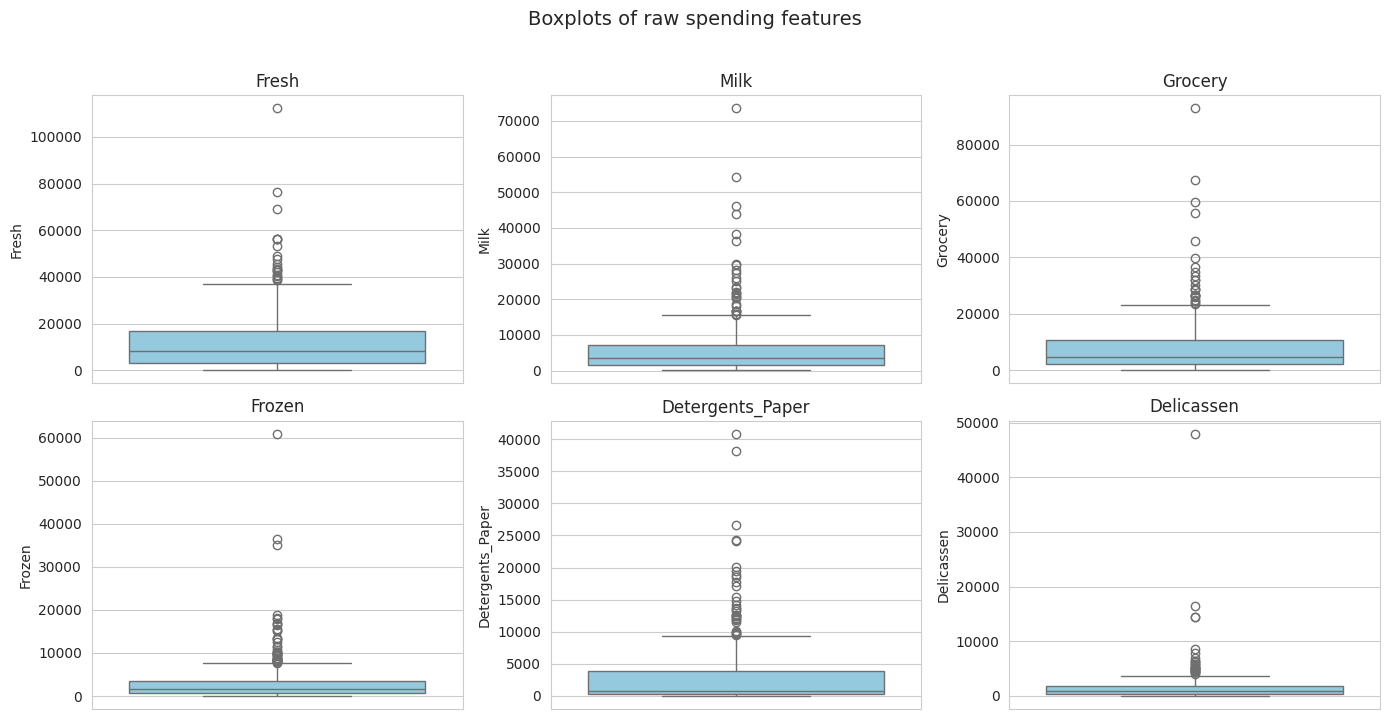

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.ravel(), features):
    sns.boxplot(y=X[col], ax=ax, color='skyblue')
    ax.set_title(col)
plt.suptitle('Boxplots of raw spending features', y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

In [11]:
# Outlier count per feature using the 1.5 * IQR rule, plus skewness
q1, q3 = X.quantile(0.25), X.quantile(0.75)
iqr = q3 - q1
outliers = ((X < q1 - 1.5 * iqr) | (X > q3 + 1.5 * iqr)).sum()
summary = pd.DataFrame({'outliers (IQR rule)': outliers,
                        'skewness (raw)': X.skew(),
                        'skewness (log1p)': np.log1p(X).skew()}).round(2)
summary

,outliers (IQR rule),skewness (raw),skewness (log1p)
Fresh,20,2.56,-1.58
Milk,28,4.05,-0.22
Grocery,24,3.59,-0.67
Frozen,43,5.91,-0.35
Detergents_Paper,30,3.63,-0.24
Delicassen,27,11.15,-1.09


### 3.3 Log transform and feature scaling
Because the features are heavily right-skewed with extreme values, we apply `np.log1p` first, then standardize with `StandardScaler` (mean 0, std 1) so every feature contributes equally to distance calculations.

In [12]:
X_log = np.log1p(X)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_log)
X_scaled_df = pd.DataFrame(X_scaled, columns=features)
X_scaled_df.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
Fresh,440.0,0.0,1.001,-5.001,-0.466,0.215,0.684,1.971
Milk,440.0,-0.0,1.001,-3.795,-0.728,0.069,0.703,2.857
Grocery,440.0,-0.0,1.001,-6.355,-0.691,0.023,0.749,2.698
Frozen,440.0,0.0,1.001,-3.159,-0.541,0.022,0.682,2.900
Detergents_Paper,440.0,-0.0,1.001,-3.166,-0.726,-0.050,0.868,2.240
Delicassen,440.0,-0.0,1.001,-4.089,-0.508,0.157,0.647,3.177


## 4. K-Means Clustering

### 4.1 Elbow Method (WCSS) for K = 2 to 10
We also compute the silhouette score for each K to support the choice, because the elbow alone can be ambiguous.

In [13]:
K_range = range(2, 11)
wcss, sil_scores = [], []
for k in K_range:
    km = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=RANDOM_STATE)
    labels = km.fit_predict(X_scaled)
    wcss.append(km.inertia_)
    sil_scores.append(silhouette_score(X_scaled, labels))

k_results = pd.DataFrame({'K': list(K_range), 'WCSS (inertia)': np.round(wcss, 2),
                          'Silhouette': np.round(sil_scores, 4)})
k_results

,K,WCSS (inertia),Silhouette
0,2,1844.06,0.2903
1,3,1553.42,0.2594
2,4,1386.86,0.1885
3,5,1266.15,0.1916
4,6,1174.76,0.2009
5,7,1086.36,0.1958
6,8,1028.49,0.1852
7,9,973.14,0.1965
8,10,932.00,0.1905


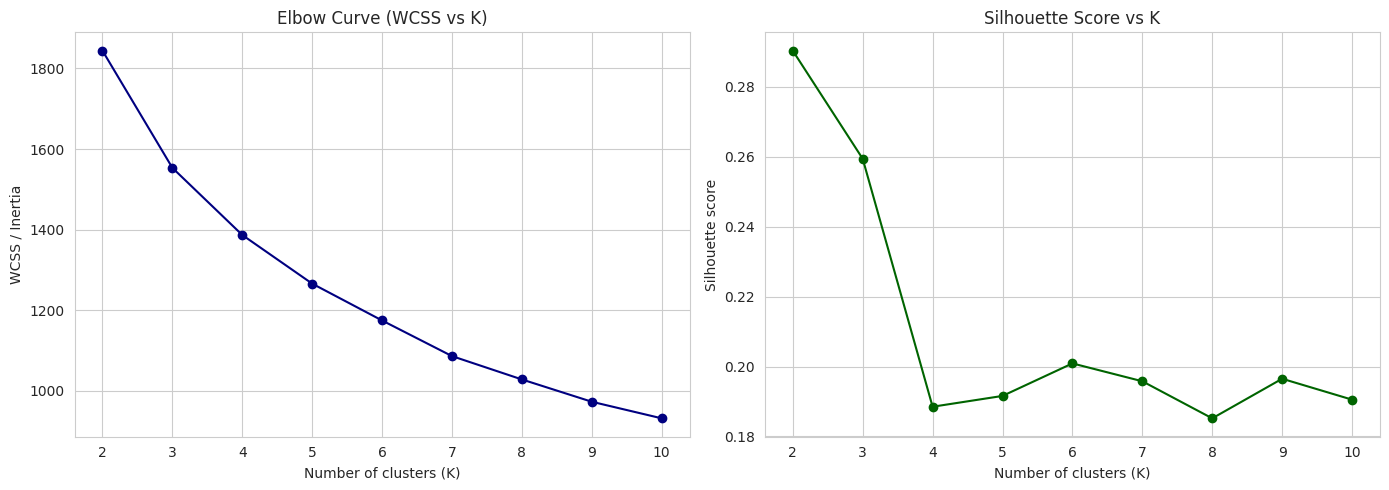

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(list(K_range), wcss, marker='o', color='navy')
axes[0].set_title('Elbow Curve (WCSS vs K)')
axes[0].set_xlabel('Number of clusters (K)')
axes[0].set_ylabel('WCSS / Inertia')

axes[1].plot(list(K_range), sil_scores, marker='o', color='darkgreen')
axes[1].set_title('Silhouette Score vs K')
axes[1].set_xlabel('Number of clusters (K)')
axes[1].set_ylabel('Silhouette score')

plt.tight_layout()
plt.show()

**Choosing K**
- WCSS falls steeply from K=2 to K=3 (about 1844 to 1553) and then more gently (1387 at K=4, 1266 at K=5), so the elbow is mild and sits around K=3 to 4.
- Silhouette is highest at K=2 (0.290) and drops to 0.259 at K=3, then falls to about 0.19 for K=4 and above.
- K=2 mostly reproduces a coarse split of the customer base. **K=3 is the largest K before the silhouette score drops sharply**, and it still gives a more informative segmentation, so we select **K=3**. The elbow is not sharp on this dataset, which is why the silhouette curve is used alongside it.

### 4.2 Apply K-Means with the selected K

In [15]:
K_OPT = 3   # chosen from elbow curve + silhouette analysis (see discussion above)

kmeans = KMeans(n_clusters=K_OPT, init='k-means++', n_init=10, random_state=RANDOM_STATE)
df['KMeans_Cluster'] = kmeans.fit_predict(X_scaled)
print('K-Means applied with K =', K_OPT)

K-Means applied with K = 3


## 5. Evaluate K-Means

In [16]:
kmeans_sil = silhouette_score(X_scaled, df['KMeans_Cluster'])
print(f'K-Means Silhouette Score (K={K_OPT}): {kmeans_sil:.4f}')
print(f'K-Means WCSS (inertia): {kmeans.inertia_:.2f}')
print('\nCustomers per cluster:')
km_sizes = df['KMeans_Cluster'].value_counts().sort_index()
km_sizes.rename('Customers').to_frame().assign(Percent=lambda d: (d['Customers']/len(df)*100).round(1))

K-Means Silhouette Score (K=3): 0.2594
K-Means WCSS (inertia): 1553.42

Customers per cluster:


,Customers,Percent
KMeans_Cluster,,
0,80,18.2
1,147,33.4
2,213,48.4


## 6. Hierarchical Clustering

### 6.1 Linkage matrix (Ward linkage, Euclidean distance)

In [17]:
Z = linkage(X_scaled, method='ward')
print('Linkage matrix shape:', Z.shape)
print('(each row: cluster i, cluster j, distance, size of the new cluster)')
pd.DataFrame(Z[:5], columns=['Cluster 1', 'Cluster 2', 'Distance', 'Size']).round(3)

Linkage matrix shape: (439, 4)
(each row: cluster i, cluster j, distance, size of the new cluster)


,Cluster 1,Cluster 2,Distance,Size
0,63.0,107.0,0.203,2.0
1,158.0,197.0,0.241,2.0
2,321.0,330.0,0.266,2.0
3,293.0,416.0,0.278,2.0
4,163.0,349.0,0.296,2.0


### 6.2 Dendrogram

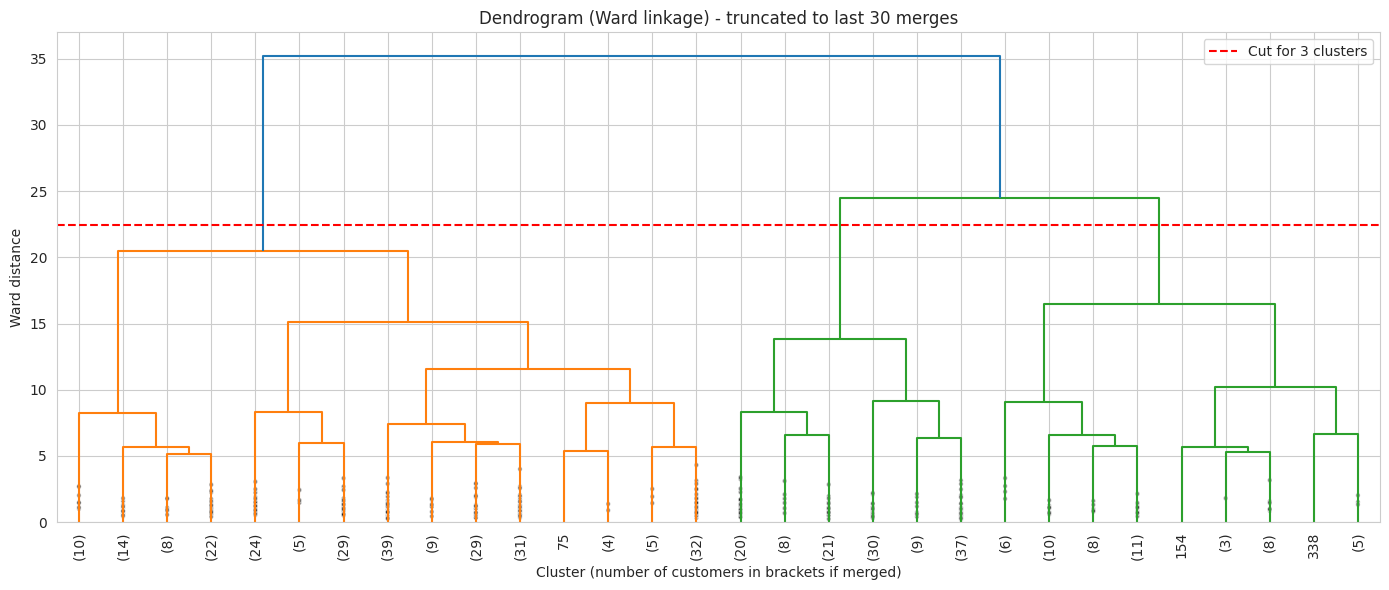

In [18]:
plt.figure(figsize=(14, 6))
dendrogram(Z, truncate_mode='lastp', p=30, leaf_rotation=90., leaf_font_size=10,
           show_contracted=True)
plt.title('Dendrogram (Ward linkage) - truncated to last 30 merges')
plt.xlabel('Cluster (number of customers in brackets if merged)')
plt.ylabel('Ward distance')
# cut midway between the merge that creates K_OPT clusters and the merge that reduces K_OPT to K_OPT-1
cut_height = (Z[-K_OPT, 2] + Z[-(K_OPT - 1), 2]) / 2
plt.axhline(y=cut_height, color='red', linestyle='--', label=f'Cut for {K_OPT} clusters')
plt.legend()
plt.tight_layout()
plt.show()

In [19]:
# Distance at which k clusters get merged into k-1 clusters (read from the top of the dendrogram).
# A large distance means the k clusters were still well separated, so a cut with k clusters is natural.
rows = []
for k in range(2, 9):
    rows.append({'k clusters -> k-1': f'{k} -> {k-1}', 'Merge distance': round(Z[-(k-1), 2], 3)})
merge_df = pd.DataFrame(rows)
merge_df['Gap to next merge'] = merge_df['Merge distance'] - merge_df['Merge distance'].shift(-1)
merge_df.round(3)

,k clusters -> k-1,Merge distance,Gap to next merge
0,2 -> 1,35.233,10.781
1,3 -> 2,24.452,3.984
2,4 -> 3,20.468,3.995
3,5 -> 4,16.473,1.388
4,6 -> 5,15.085,1.231
5,7 -> 6,13.854,2.272
6,8 -> 7,11.582,NaN


**Choosing the number of clusters from the dendrogram**
- The largest vertical gap is for the final merge (2 clusters into 1), so a 2-cluster cut is the most obvious one.
- The next gaps are for the 3 to 2 and 4 to 3 merges and are similar in size to each other. Hierarchical silhouette scores are 0.2585 for 2 clusters and 0.2547 for 3 clusters, then drop to about 0.20 for 4.
- We cut at **3 clusters** (red dashed line). This matches K-Means, which keeps the comparison fair, and loses almost no silhouette quality compared with 2 clusters.

### 6.3 Silhouette scores for different cluster counts (supporting the cut)

In [20]:
h_sil = {}
for k in range(2, 11):
    lab = AgglomerativeClustering(n_clusters=k, linkage='ward').fit_predict(X_scaled)
    h_sil[k] = silhouette_score(X_scaled, lab)
pd.Series(h_sil, name='Silhouette').rename_axis('n_clusters').round(4).to_frame()

,Silhouette
n_clusters,
2,0.2585
3,0.2547
4,0.2021
5,0.2025
6,0.1707
7,0.1633
8,0.1482
9,0.1555
10,0.1218


### 6.4 Apply Agglomerative Hierarchical Clustering

In [21]:
N_HC = 3   # selected number of clusters, same as K-Means for a fair comparison
hc = AgglomerativeClustering(n_clusters=N_HC, linkage='ward')   # Euclidean distance by default with Ward
df['HC_Cluster'] = hc.fit_predict(X_scaled)
print('Agglomerative clustering applied with n_clusters =', N_HC)

Agglomerative clustering applied with n_clusters = 3


## 7. Evaluate Hierarchical Clustering

In [22]:
hc_sil = silhouette_score(X_scaled, df['HC_Cluster'])
print(f'Hierarchical Silhouette Score (n={N_HC}): {hc_sil:.4f}')
print('\nCustomers per cluster:')
hc_sizes = df['HC_Cluster'].value_counts().sort_index()
hc_sizes.rename('Customers').to_frame().assign(Percent=lambda d: (d['Customers']/len(df)*100).round(1))

Hierarchical Silhouette Score (n=3): 0.2547

Customers per cluster:


,Customers,Percent
HC_Cluster,,
0,262,59.5
1,53,12.0
2,125,28.4


## 8. Analyze the generated clusters

### 8.1 Cluster profiles: mean spending per feature (original, unscaled units)

In [23]:
km_profile = df.groupby('KMeans_Cluster')[features].mean().round(1)
km_profile['Customers'] = km_sizes
print('K-Means cluster profile')
km_profile



hc_profile = df.groupby('HC_Cluster')[features].mean().round(1)
hc_profile['Customers'] = hc_sizes
print('Hierarchical cluster profile')
hc_profile

K-Means cluster profile
Hierarchical cluster profile


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,Customers
HC_Cluster,,,,,,,
0,15016.1,3389.9,3674.0,4187.9,616.8,1552.8,262
1,3914.0,5223.0,8657.9,1198.4,3474.1,190.5,53
2,9107.8,11083.0,16616.9,1527.3,7377.0,2032.2,125


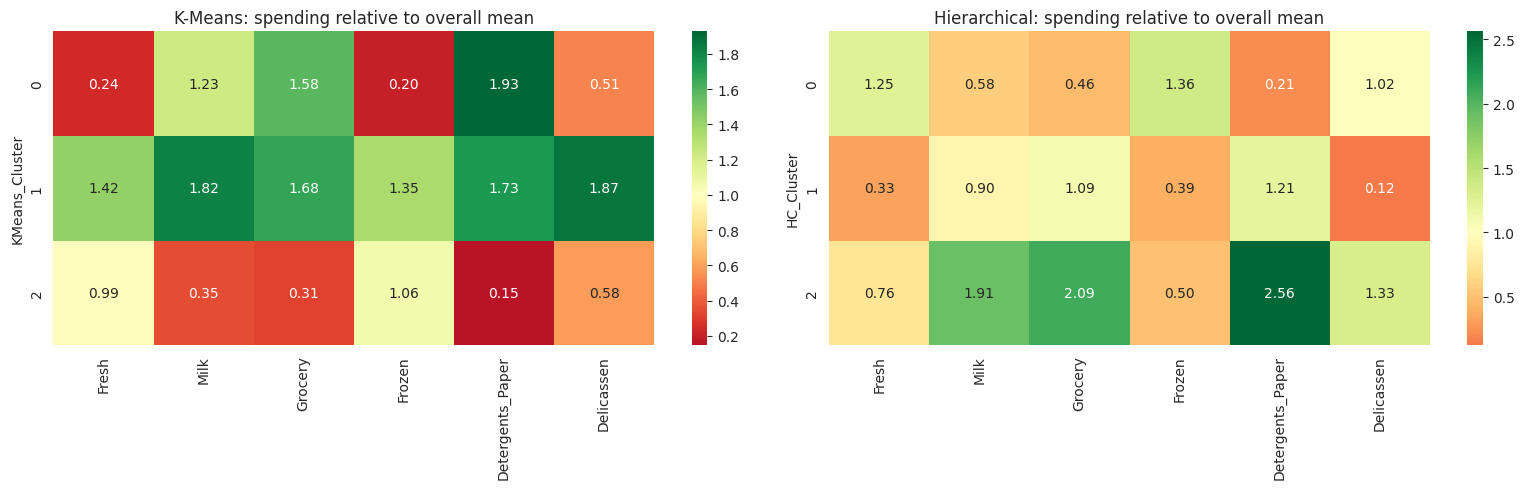

In [24]:
# Relative profile: each cluster's mean spend divided by the overall mean (1.0 = average customer)
overall = df[features].mean()
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.heatmap(km_profile[features] / overall, annot=True, fmt='.2f', cmap='RdYlGn', center=1, ax=axes[0])
axes[0].set_title('K-Means: spending relative to overall mean')
sns.heatmap(hc_profile[features] / overall, annot=True, fmt='.2f', cmap='RdYlGn', center=1, ax=axes[1])
axes[1].set_title('Hierarchical: spending relative to overall mean')
plt.tight_layout()
plt.show()

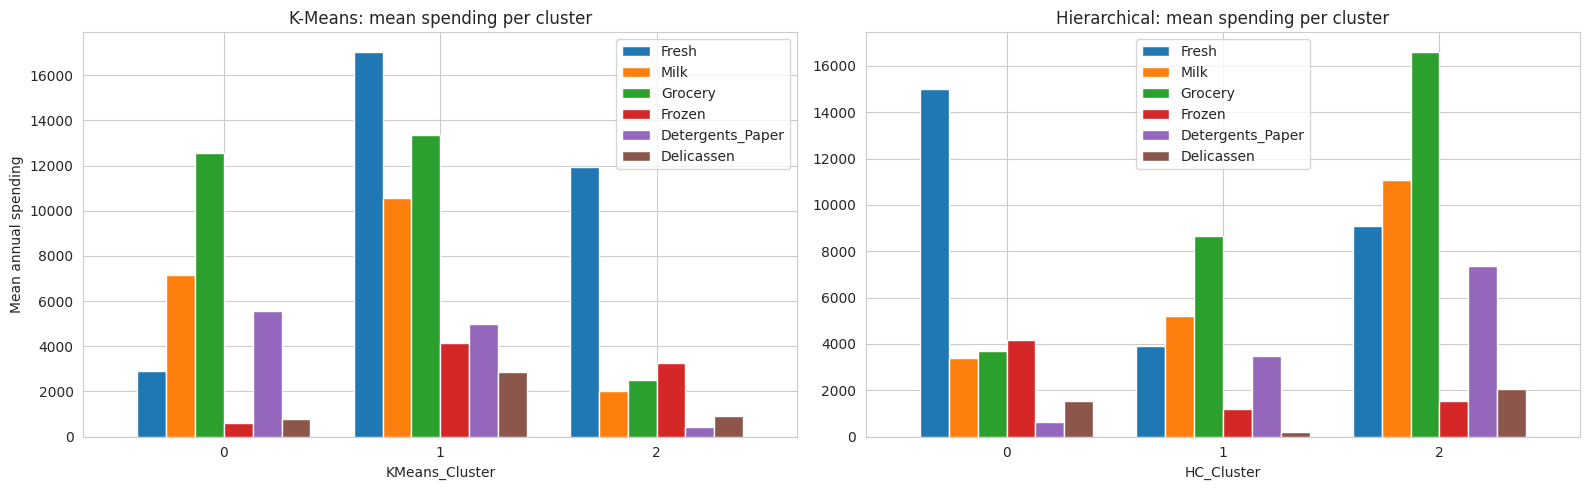

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
km_profile[features].plot(kind='bar', ax=axes[0], width=0.8)
axes[0].set_title('K-Means: mean spending per cluster')
axes[0].set_ylabel('Mean annual spending')
axes[0].tick_params(axis='x', rotation=0)
hc_profile[features].plot(kind='bar', ax=axes[1], width=0.8)
axes[1].set_title('Hierarchical: mean spending per cluster')
axes[1].tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()

### 8.2 Do the clusters make real-world sense? Cross-tabulation with `Channel` and `Region`
`Channel` (1 = Horeca: hotels/restaurants/cafés, 2 = Retail) was not used for clustering, so agreement here is independent validation.

In [26]:
for name in ['KMeans_Cluster', 'HC_Cluster']:
    print(f'--- {name} vs Channel (row %) ---')
    ct = pd.crosstab(df[name], df['Channel'].map({1: 'Horeca', 2: 'Retail'}), normalize='index').mul(100).round(1)
    ct['Customers'] = df[name].value_counts().sort_index()
    print(ct, '\n')

--- KMeans_Cluster vs Channel (row %) ---
Channel         Horeca  Retail  Customers
KMeans_Cluster                           
0                 40.0    60.0         80
1                 38.1    61.9        147
2                 98.6     1.4        213 

--- HC_Cluster vs Channel (row %) ---
Channel     Horeca  Retail  Customers
HC_Cluster                           
0             95.8     4.2        262
1             50.9    49.1         53
2             16.0    84.0        125 



In [27]:
for name in ['KMeans_Cluster', 'HC_Cluster']:
    print(f'--- {name} vs Region (row %) ---')
    print(pd.crosstab(df[name], df['Region'].map({1: 'Lisbon', 2: 'Oporto', 3: 'Other'}), normalize='index').mul(100).round(1), '\n')

--- KMeans_Cluster vs Region (row %) ---
Region          Lisbon  Oporto  Other
KMeans_Cluster                       
0                 17.5    12.5   70.0
1                 15.6     7.5   76.9
2                 18.8    12.2   69.0 

--- HC_Cluster vs Region (row %) ---
Region      Lisbon  Oporto  Other
HC_Cluster                       
0             19.5    10.3   70.2
1             11.3    13.2   75.5
2             16.0    10.4   73.6 



## 9. Compare K-Means and Hierarchical Clustering

In [28]:
from sklearn.metrics import adjusted_rand_score
comparison = pd.DataFrame({
    'Method': ['K-Means', 'Hierarchical (Ward)'],
    'Clusters': [K_OPT, N_HC],
    'Cluster sizes': [list(km_sizes.values), list(hc_sizes.values)],
    'Silhouette score': [round(kmeans_sil, 4), round(hc_sil, 4)],
})
comparison

,Method,Clusters,Cluster sizes,Silhouette score
0,K-Means,3,"[80, 147, 213]",0.2594
1,Hierarchical (Ward),3,"[262, 53, 125]",0.2547


In [29]:
print('Agreement between the two clusterings (Adjusted Rand Index):',
      round(adjusted_rand_score(df['KMeans_Cluster'], df['HC_Cluster']), 4))
print('\nCross-tab of K-Means vs Hierarchical labels:')
pd.crosstab(df['KMeans_Cluster'], df['HC_Cluster'], rownames=['K-Means'], colnames=['Hierarchical'])

Agreement between the two clusterings (Adjusted Rand Index): 0.4491

Cross-tab of K-Means vs Hierarchical labels:


Hierarchical,0,1,2
K-Means,,,
0,10,36,34
1,50,6,91
2,202,11,0


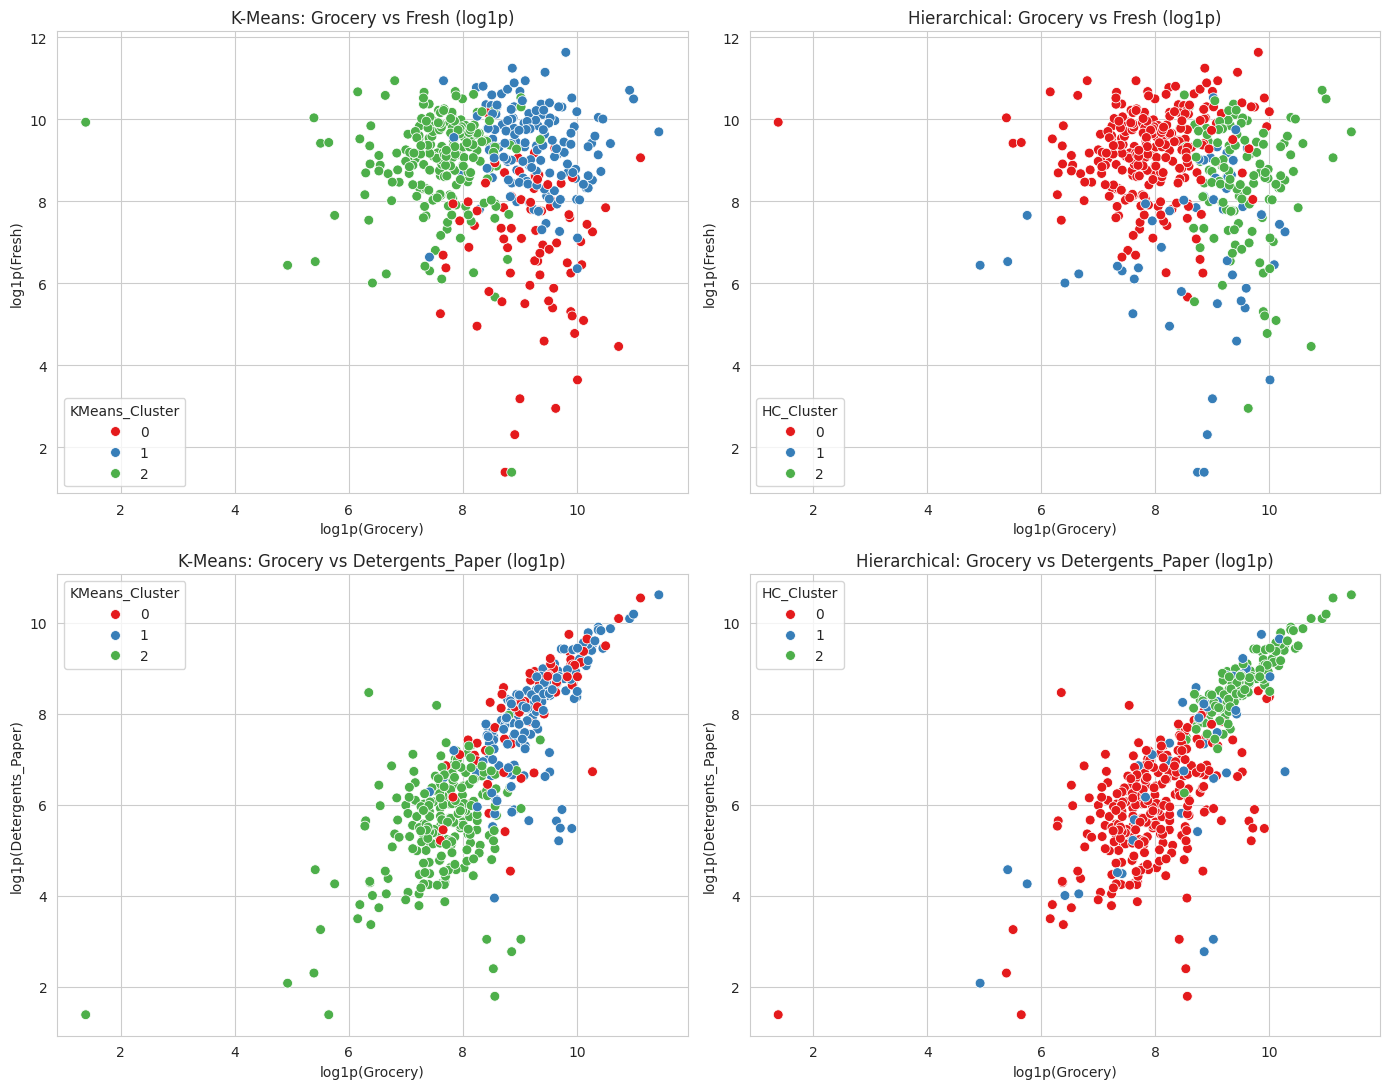

In [30]:

fig, axes = plt.subplots(2, 2, figsize=(14, 11))
pairs = [('Grocery', 'Fresh'), ('Grocery', 'Detergents_Paper')]
for r, (xcol, ycol) in enumerate(pairs):
    for c, (lab, title) in enumerate([('KMeans_Cluster', 'K-Means'), ('HC_Cluster', 'Hierarchical')]):
        sns.scatterplot(x=np.log1p(df[xcol]), y=np.log1p(df[ycol]), hue=df[lab],
                        palette='Set1', s=50, ax=axes[r, c])
        axes[r, c].set_title(f'{title}: {xcol} vs {ycol} (log1p)')
        axes[r, c].set_xlabel(f'log1p({xcol})')
        axes[r, c].set_ylabel(f'log1p({ycol})')
plt.tight_layout()
plt.show()